<a href="https://colab.research.google.com/github/Andres10-cmd/aiml-pro1/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving loan_default_dataset.csv to loan_default_dataset (1).csv
(1000, 10) | default rate: 0.298


,age,annual_income,loan_amount,credit_score,employment_years,debt_to_income,num_credit_lines,home_ownership,loan_purpose,defaulted
0,25,38800,25800,674,0,0.420,5,Mortgage,Home improvement,1
1,55,103500,60000,671,26,0.457,6,Rent,Home improvement,0
2,50,67700,7000,754,23,0.439,4,Mortgage,Debt consolidation,0
3,40,52000,12900,671,9,0.332,4,Rent,Other,1
4,40,60900,37100,673,18,0.522,7,Mortgage,Education,0


              precision    recall  f1-score   support

           0       0.76      0.91      0.83       140
           1       0.62      0.33      0.43        60

    accuracy                           0.74       200
   macro avg       0.69      0.62      0.63       200
weighted avg       0.72      0.74      0.71       200

ROC AUC: 0.743


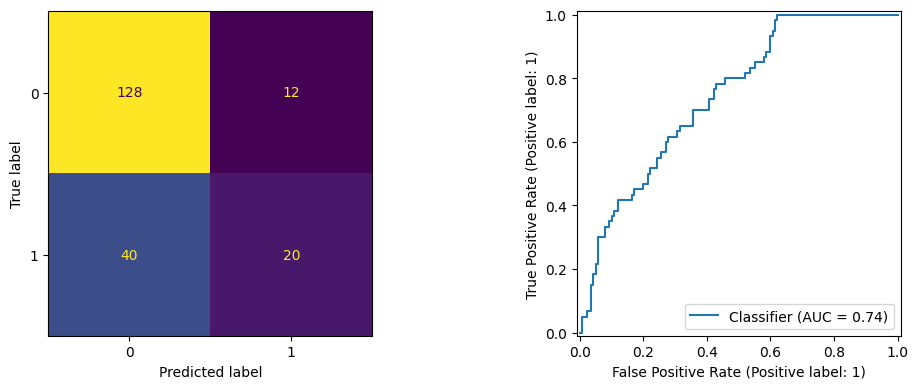

,feature,coef,odds_ratio
3,num__credit_score,-0.878067,0.415585
7,cat__home_ownership_Own,-0.649180,0.522474
4,num__employment_years,-0.550081,0.576903
11,cat__loan_purpose_Home improvement,-0.444523,0.641130
2,num__loan_amount,0.423368,1.527097
1,num__annual_income,-0.380574,0.683469
10,cat__loan_purpose_Education,-0.292070,0.746717
5,num__debt_to_income,0.285285,1.330141
0,num__age,0.196978,1.217717
6,num__num_credit_lines,-0.161280,0.851053


In [ ]:
import io
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

# ---------- 1. Load the dataset ----------
uploaded = files.upload()                      # choose loan_default_dataset.csv
df = pd.read_csv(io.BytesIO(uploaded[next(iter(uploaded))]))
df = df.drop(columns="customer_id")

print(df.shape, "| default rate:", df["defaulted"].mean().round(3))
display(df.head())

# ---------- 2. Train/test split ----------
X, y = df.drop(columns="defaulted"), df["defaulted"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)

# ---------- 3. Preprocess + model ----------
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = ["home_ownership", "loan_purpose"]

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first"), cat_cols),
])
model = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000))])
model.fit(Xtr, ytr)

# ---------- 4. Evaluate ----------
pred = model.predict(Xte)
proba = model.predict_proba(Xte)[:, 1]
print(classification_report(yte, pred))
print("ROC AUC:", round(roc_auc_score(yte, proba), 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(yte, pred)).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(yte, proba, ax=ax[1])
plt.tight_layout(); plt.show()

# ---------- 5. Coefficients (odds ratios) ----------
names = model.named_steps["pre"].get_feature_names_out()
coefs = model.named_steps["lr"].coef_[0]
coef_df = (pd.DataFrame({"feature": names, "coef": coefs, "odds_ratio": np.exp(coefs)})
           .sort_values("coef", key=abs, ascending=False))
display(coef_df)

In [ ]:
import ipywidgets as w
from IPython.display import display, clear_output

f = dict(
    age=w.IntSlider(value=35, min=21, max=65, description="Age"),
    annual_income=w.IntText(value=55000, description="Income"),
    loan_amount=w.IntText(value=15000, description="Loan"),
    credit_score=w.IntSlider(value=680, min=450, max=850, description="Credit"),
    employment_years=w.IntSlider(value=8, min=0, max=40, description="Emp. yrs"),
    debt_to_income=w.FloatSlider(value=0.30, min=0.02, max=0.75, step=0.01, description="DTI"),
    num_credit_lines=w.IntSlider(value=5, min=1, max=15, description="Cred. lines"),
    home_ownership=w.Dropdown(options=["Rent", "Mortgage", "Own"], description="Home"),
    loan_purpose=w.Dropdown(options=["Debt consolidation", "Home improvement", "Education",
                                     "Medical", "Business", "Other"], description="Purpose"),
)
btn, out = w.Button(description="Predict", button_style="primary"), w.Output()

def on_click(_):
    row = pd.DataFrame([{k: v.value for k, v in f.items()}])
    p = model.predict_proba(row)[0, 1]
    with out:
        clear_output()
        print(f"Default probability: {p:.1%}")
        print("⚠️ High risk" if p >= 0.5 else "✅ Low risk")

btn.on_click(on_click)
display(*f.values(), btn, out)

IntSlider(value=35, description='Age', max=65, min=21)

IntText(value=55000, description='Income')

IntText(value=15000, description='Loan')

IntSlider(value=680, description='Credit', max=850, min=450)

IntSlider(value=8, description='Emp. yrs', max=40)

...

IntSlider(value=5, description='Cred. lines', max=15, min=1)

Dropdown(description='Home', options=('Rent', 'Mortgage', 'Own'), value='Rent')

Dropdown(description='Purpose', options=('Debt consolidation', 'Home improvement', 'Education', 'Medical', 'Bu…

Button(button_style='primary', description='Predict', style=ButtonStyle())

Output()

In [ ]:
!pip install -q gradio

import gradio as gr
import pandas as pd

def predict(age, income, loan, credit, emp, dti, lines, home, purpose, threshold):
    row = pd.DataFrame([{
        "age": age, "annual_income": income, "loan_amount": loan,
        "credit_score": credit, "employment_years": emp,
        "debt_to_income": dti, "num_credit_lines": lines,
        "home_ownership": home, "loan_purpose": purpose,
    }])
    p = model.predict_proba(row)[0, 1]
    verdict = ("⚠️ High risk: likely to DEFAULT" if p >= threshold
               else "✅ Low risk: likely to REPAY")
    return verdict, {"Default": float(p), "Repay": float(1 - p)}

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Slider(21, 65, value=35, step=1, label="Age"),
        gr.Number(value=55000, label="Annual income"),
        gr.Number(value=15000, label="Loan amount"),
        gr.Slider(450, 850, value=680, step=1, label="Credit score"),
        gr.Slider(0, 40, value=8, step=1, label="Employment years"),
        gr.Slider(0.02, 0.75, value=0.30, step=0.01, label="Debt-to-income ratio"),
        gr.Slider(1, 15, value=5, step=1, label="Number of credit lines"),
        gr.Dropdown(["Rent", "Mortgage", "Own"], value="Rent", label="Home ownership"),
        gr.Dropdown(["Debt consolidation", "Home improvement", "Education",
                     "Medical", "Business", "Other"],
                    value="Debt consolidation", label="Loan purpose"),
        gr.Slider(0.1, 0.9, value=0.5, step=0.05, label="Decision threshold"),
    ],
    outputs=[gr.Textbox(label="Prediction"), gr.Label(label="Probability")],
    title="Loan Default Predictor",
    description="Enter applicant details to estimate default risk.",
    flagging_mode="never",
)

demo.launch(share=True)   # prints a public link that works for ~72 hours

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://09c581328b6f9ccf2b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install -q "gradio<6"

import gradio as gr
import numpy as np
import pandas as pd

# ---------------- Config ----------------
HOME = ["Rent", "Mortgage", "Own"]
PURPOSE = ["Debt consolidation", "Home improvement", "Education",
           "Medical", "Business", "Other"]

NICE = {"age": "Age", "annual_income": "Annual income", "loan_amount": "Loan amount",
        "credit_score": "Credit score", "employment_years": "Employment years",
        "debt_to_income": "Debt-to-income", "num_credit_lines": "Credit lines"}

def nice_name(raw):
    raw = raw.split("__", 1)[-1]
    if raw.startswith("home_ownership_"):
        return "Home: " + raw.replace("home_ownership_", "")
    if raw.startswith("loan_purpose_"):
        return "Purpose: " + raw.replace("loan_purpose_", "")
    return NICE.get(raw, raw)

# ---------------- Prediction logic ----------------
def drivers(row, top=5):
    pre, lr = model.named_steps["pre"], model.named_steps["lr"]
    x = pre.transform(row)
    x = x.toarray() if hasattr(x, "toarray") else x
    s = pd.Series(x[0] * lr.coef_[0], index=pre.get_feature_names_out())
    s = s[s.abs() > 1e-9]
    return s.reindex(s.abs().sort_values(ascending=False).index).head(top)

def render(p, d, lti):
    if p < 0.25:   tier, color, bg = "LOW RISK", "#15803d", "#f0fdf4"
    elif p < 0.50: tier, color, bg = "MODERATE RISK", "#b45309", "#fffbeb"
    else:          tier, color, bg = "HIGH RISK", "#b91c1c", "#fef2f2"

    mx = max(d.abs().max(), 1e-9)
    rows = ""
    for name, v in d.items():
        up = v > 0
        c = "#dc2626" if up else "#16a34a"
        w = max(6, int(abs(v) / mx * 100))
        rows += f"""
        <div class="drv">
          <span class="drv-name">{nice_name(name)}</span>
          <div class="drv-track"><div style="width:{w}%;background:{c}"></div></div>
          <span class="drv-tag" style="color:{c}">{'▲ raises' if up else '▼ lowers'}</span>
        </div>"""

    return f"""
    <div class="card" style="background:{bg};border-color:{color}">
      <div class="tier" style="color:{color}">{tier}</div>
      <div class="prob" style="color:{color}">{p:.1%}</div>
      <div class="sub">estimated probability of default</div>
      <div class="gauge">
        <div class="gauge-bar"></div>
        <div class="gauge-mark" style="left:{min(p,1)*100:.1f}%"></div>
      </div>
      <div class="scale"><span>0%</span><span>25%</span><span>50%</span><span>100%</span></div>
    </div>
    <div class="card plain">
      <div class="sect">Key factors behind this result</div>
      {rows}
      <div class="note">Loan-to-income ratio: <b>{lti:.0%}</b></div>
    </div>"""

def predict(age, income, loan, credit, emp, dti, lines, home, purpose):
    if not income or income <= 0 or loan is None or loan < 0:
        return "<div class='card plain'>Enter a valid income and loan amount.</div>"
    row = pd.DataFrame([{
        "age": age, "annual_income": income, "loan_amount": loan,
        "credit_score": credit, "employment_years": emp, "debt_to_income": dti,
        "num_credit_lines": lines, "home_ownership": home, "loan_purpose": purpose}])
    p = float(model.predict_proba(row)[0, 1])
    return render(p, drivers(row), loan / income)

# ---------------- Styling ----------------
CSS = """
.gradio-container {max-width: 1150px !important; margin: auto;}
.hero {background: linear-gradient(120deg,#0f172a,#1e40af); color:#fff;
       padding: 26px 30px; border-radius: 14px; margin-bottom: 14px;}
.hero h1 {margin:0; font-size: 26px; font-weight: 700; color:#fff;}
.hero p {margin:6px 0 0; opacity:.85; font-size: 14px; color:#fff;}
.card {border:1.5px solid #e5e7eb; border-radius:14px; padding:22px; margin-bottom:14px;
       text-align:center; color:#111827;}
.card.plain {background:#fff; text-align:left;}
.tier {font-weight:700; letter-spacing:.12em; font-size:13px;}
.prob {font-size:56px; font-weight:800; line-height:1.1; margin:4px 0;}
.sub {font-size:13px; color:#4b5563; margin-bottom:16px;}
.gauge {position:relative; height:12px; margin:0 6px;}
.gauge-bar {height:12px; border-radius:6px;
   background:linear-gradient(90deg,#22c55e 0%,#eab308 35%,#ef4444 70%);}
.gauge-mark {position:absolute; top:-5px; width:4px; height:22px; background:#111827;
   border-radius:2px; transform:translateX(-2px);}
.scale {display:flex; justify-content:space-between; font-size:11px; color:#6b7280; margin:8px 6px 0;}
.sect {font-weight:600; font-size:14px; margin-bottom:12px; color:#111827;}
.drv {display:grid; grid-template-columns: 150px 1fr 80px; gap:10px; align-items:center; margin:8px 0;}
.drv-name {font-size:13px; color:#374151;}
.drv-track {background:#f3f4f6; height:8px; border-radius:4px; overflow:hidden;}
.drv-track div {height:8px; border-radius:4px;}
.drv-tag {font-size:12px; font-weight:600; text-align:right;}
.note {margin-top:14px; padding-top:12px; border-top:1px solid #e5e7eb; font-size:13px; color:#4b5563;}
.foot {text-align:center; font-size:12px; color:#6b7280; margin-top:10px;}
"""

theme = gr.themes.Soft(primary_hue="blue", neutral_hue="slate",
                       font=[gr.themes.GoogleFont("Inter"), "sans-serif"])

DEFAULTS = [35, 55000, 15000, 680, 8, 0.30, 5, "Rent", "Debt consolidation"]

# ---------------- Layout ----------------
with gr.Blocks(theme=theme, css=CSS, title="Loan Default Risk Predictor") as demo:
    gr.HTML("""<div class="hero"><h1>Loan Default Risk Predictor</h1>
    <p>Adjust the applicant details and the risk estimate updates instantly.</p></div>""")

    with gr.Row(equal_height=False):
        with gr.Column(scale=5):
            with gr.Group():
                gr.Markdown("#### 👤 Applicant profile")
                age = gr.Slider(21, 65, value=DEFAULTS[0], step=1, label="Age")
                emp = gr.Slider(0, 40, value=DEFAULTS[4], step=1, label="Employment (years)")
                home = gr.Radio(HOME, value=DEFAULTS[7], label="Home ownership")
            with gr.Group():
                gr.Markdown("#### 💳 Financial standing")
                income = gr.Number(value=DEFAULTS[1], label="Annual income", minimum=0)
                credit = gr.Slider(450, 850, value=DEFAULTS[3], step=1, label="Credit score")
                dti = gr.Slider(0.02, 0.75, value=DEFAULTS[5], step=0.01, label="Debt-to-income ratio")
                lines = gr.Slider(1, 15, value=DEFAULTS[6], step=1, label="Open credit lines")
            with gr.Group():
                gr.Markdown("#### 🏦 Loan request")
                loan = gr.Number(value=DEFAULTS[2], label="Loan amount", minimum=0)
                purpose = gr.Dropdown(PURPOSE, value=DEFAULTS[8], label="Loan purpose")
            reset = gr.Button("↺ Reset to defaults", variant="secondary")

        with gr.Column(scale=4):
            out = gr.HTML()

    inputs = [age, income, loan, credit, emp, dti, lines, home, purpose]

    gr.Examples(
        examples=[
            [28, 32000, 28000, 590, 2, 0.52, 9, "Rent", "Business"],
            [45, 85000, 12000, 740, 18, 0.22, 4, "Mortgage", "Home improvement"],
            [58, 120000, 20000, 800, 30, 0.15, 3, "Own", "Education"],
        ],
        inputs=inputs, label="Try a sample applicant")

    gr.HTML('<div class="foot">Statistical model trained on synthetic data. '
            'For demonstration only, not for real credit decisions.</div>')

    # live updates on every change + on page load
    gr.on(triggers=[c.change for c in inputs], fn=predict, inputs=inputs,
          outputs=out, show_progress="hidden")
    demo.load(predict, inputs, out)
    reset.click(lambda: DEFAULTS, None, inputs)

demo.launch(share=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.7/87.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.5/63.5 MB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.6/325.6 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 462.4/462.4 kB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 116.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.3/74.3 kB 5.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hf-gradio 0.4.1 requires gradio-client<3.0,>=2.0, but you have gradio-client 1.14.0 which is incompatible.
python-fasthtml 0.14.13 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you hav

/tmp/ipykernel_1522/4278702555.py:113: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=theme, css=CSS, title="Loan Default Risk Predictor") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e1a66453532e5a5592.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
